In [34]:
import kan, torch
import pandas as pd
import numpy as np
import os
import re
import matplotlib.pyplot as plt
from kan import ex_round
from torch.utils.flop_counter import FlopCounterMode
from pathlib import Path

# These functions: _n   _pw   _red   
# are used for counting the computational cost of training and testing the model
def _n(shape):
    if isinstance(shape, torch.Size): return shape.numel()
    if isinstance(shape, (tuple, list)): return sum(_n(s) for s in shape)
    return 0

def _pw(cost):                       # cost per output element
    def f(*args, out_shape=None, **kw): return cost * _n(out_shape)
    return f

def _red(cost):                      # cost per input element
    def f(in_shape, *args, out_shape=None, **kw): return cost * _n(in_shape)
    return f

aten = torch.ops.aten
# Convention: add/sub/mul/div/compare/where = 1 FLOP, sigmoid = 1, silu = 2
CUSTOM = {
    **{op: _pw(1) for op in [aten.add, aten.add_, aten.sub, aten.sub_, aten.rsub,
        aten.mul, aten.mul_, aten.div, aten.div_, aten.neg, aten.ge, aten.gt,
        aten.le, aten.lt, aten.eq, aten.ne, aten.where, aten.nan_to_num,
        aten.sigmoid, aten.sqrt, aten.addcmul_, aten.addcdiv_, aten.lerp_,
        aten._foreach_add_, aten._foreach_mul_, aten._foreach_div_,
        aten._foreach_sqrt, aten._foreach_addcmul_, aten._foreach_addcdiv_,
        aten.abs, aten.sgn, aten.pow, aten.log2]},
    aten.silu: _pw(2),
    aten.silu_backward: _pw(5),
    aten.sigmoid_backward: _pw(3),
    aten.sum: _red(1), aten.mean: _red(1),
    aten.std: _red(4), aten.var: _red(4),
}
def flop_counter():
    return FlopCounterMode(display=False, custom_mapping=CUSTOM)

# Without the functions above, counting the computational cost via FLOPs would be a lower bound
# because a lot of things would not be counted.


# To read files from a directory and output a list that contains all of their experiment numbers
DIRECTORY = Path("data_for_model/")
EXTENSION = ".csv"
PATTERN = re.compile(r"LFXR_Lovejoy_Sept2021_(\d+)")  # capture group = the number

def get_file_numbers():
    numbers = []
    for f in DIRECTORY.glob(f"*{EXTENSION}"):
        match = PATTERN.search(f.stem)
        if match:
            numbers.append(int(match.group(1)))
    return sorted(numbers)



def normalize(x):  # min-max scaling
    if x.min() == x.max():
        return (x*0 + 1)
    return (x - x.min()) / (x.max() - x.min())

def denormalize(x, x_min, x_max):  # min-max unscaling
    return x * (x_max - x_min) + x_min

def train_model(expmnt, kan_width, kan_grid, kan_k, all_time, all_PCD, all_volt, all_bias, all_load, 
                time_mx_mn, PCD_mx_mn, volt_mx_mn, bias_mx_mn, load_mx_mn,
                train_losses, test_losses, train_ratio, LOO_test = False):

    # kan_width must be a list
    print(f"Training on {train_ratio*100}% of data")
    
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    #print(device)

    # initialize KAN
    model = kan.KAN(width=kan_width, grid=kan_grid, k=kan_k, seed=1, grid_range= [0,1], device=str(device))

    # declare variables used elsewhere in program.
    expmnt_size = []

    for exp_num in expmnt:
        if exp_num == 0: continue
        # collect data from dataset
        file_name = f"data_for_model\\LFXR_Lovejoy_Sept2021_{exp_num}.csv"
        df_train = pd.read_csv(file_name, usecols=[0,1,3])

        df_start_stop = pd.read_csv("start_stop_pts.csv")
        expmnt_row = exp_num - 27271   # the first experiment is on row index 1
        volt_start = int(df_start_stop['volt_start'].iloc[expmnt_row])
        volt_stop = int(df_start_stop['volt_stop'].iloc[expmnt_row])
        rad_start = int(df_start_stop['rad_start'].iloc[expmnt_row])
        rad_stop = int(df_start_stop['rad_stop'].iloc[expmnt_row])

        expmnt_size.append(volt_stop - volt_start)

        bias = float(df_start_stop['bias'].iloc[expmnt_row])
        load = float(df_start_stop['load'].iloc[expmnt_row])

        
        #print(volt_start, volt_stop, rad_start, rad_stop)

        time = df_train['time1'].iloc[volt_start:volt_stop].to_numpy(dtype = np.float32)
        # Make time in microseconds
        time = time * 1e6
        time = time - time.min() # shift time to start at 0


        PCD = df_train['PCD3_B'].iloc[rad_start:rad_stop].to_numpy(dtype = np.float32)

        # output voltage
        volt = df_train['Diode'].iloc[volt_start:volt_stop].to_numpy(dtype = np.float32) #.reshape(-1,1)
        #volt = volt / (bias if bias > 1 else 1)
    
        all_time = np.append(all_time, time)
        all_PCD = np.append(all_PCD, PCD)
        all_volt = np.append(all_volt, volt)
        all_bias = np.append(all_bias, np.full_like(time, bias))
        all_load = np.append(all_load, np.full_like(time, np.log10(load))) # use logarithmic scale for load to prevent NANs.


    # time_mx_mn[0] = all_time.max()
    # time_mx_mn[1] = all_time.min() 
    # all_time = normalize(all_time)  # normalize time to [0,1]
    all_time = (all_time - time_mx_mn[1]) / (time_mx_mn[0] - time_mx_mn[1])

    # volt_mx_mn[0] = all_volt.max()
    # volt_mx_mn[1] = all_volt.min()
    # all_volt = normalize(all_volt)  # normalize voltage to [0,1]
    all_volt = (all_volt - volt_mx_mn[1]) / (volt_mx_mn[0] - volt_mx_mn[1])

    PCD_mx_mn[0] = all_PCD.max()
    PCD_mx_mn[1] = all_PCD.min()  
    #all_PCD = normalize(all_PCD)  # normalize PCD to [0,1]
    all_PCD = (all_PCD - PCD_mx_mn[1]) / (PCD_mx_mn[0] - PCD_mx_mn[1])

    all_bias = (all_bias - bias_mx_mn[1]) / (bias_mx_mn[0] - bias_mx_mn[1])
    all_load = (all_load - load_mx_mn[1]) / (load_mx_mn[0] - load_mx_mn[1]) 

    # Make input matrix
    X = np.column_stack((all_time, all_PCD, all_bias, all_load))  # shape (num_samples, 4)


    #pull training points from the data
    np.random.seed(None)
    # need to get certain number of points from each experiment, so we don't just pull the first 70% of the data
    slice_idx = 0
    test_indices = np.array([], dtype=int)
    
    for idx, i in enumerate(expmnt):
        if i == 0: continue
        slice_idx += expmnt_size[idx]
        exp_indices = np.arange(slice_idx - expmnt_size[idx], slice_idx)
        exp_test_indices = np.random.choice(exp_indices, 
                            round(expmnt_size[idx] * (1 - train_ratio)), replace=False)
        test_indices = np.concatenate((test_indices, exp_test_indices))

    X_test = X[test_indices]
    n_volt_test = all_volt[test_indices] # Correct Answers

    #pull the rest for training
    train_indices = np.setdiff1d(np.arange(X.shape[0]), test_indices)
    X_train = X[train_indices]
    n_volt_train = all_volt[train_indices]

    dataset = {
        "train_input": torch.from_numpy(X_train).to(device),
        "train_label": torch.from_numpy(n_volt_train).reshape(-1,1).to(device),
        "test_input":  torch.from_numpy(X_test).to(device),
        "test_label":  torch.from_numpy(n_volt_test).reshape(-1,1).to(device),
    }

    print(f"Points for training: {X_train.shape}\nPoints for testing {X_test.shape}")
    
    for grid in [0]: # can be used to refine the grid of the KAN. So far, it has inconclusive/negative results
        if grid != 0:
            print(f"Refined to {kan_grid + grid}")
            model.refine(kan_grid + grid)
        with FlopCounterMode(display=False) as fc_train:
            x=5.58*93.2
        results = model.fit(dataset,
                opt="Adam", # Adam (faster) or LBFGS (slower)
                steps=300,
                lr=0.03, # was 0.016
                update_grid=False,  # set to false for single experiment training.
                start_grid_update_step= 100,
                stop_grid_update_step= 120,
                lamb=0.1,        # master scale — tune this first
                lamb_l1=0.0,      # high — you want to prune weak connections
                lamb_entropy=0.0, # high — encourages interpretable simple functions
                lamb_coef=0.0,    # usually redundant if l1 is active
                lamb_coefdiff=0.00) # smooth splines — important for noisy data)
    train_losses += results['train_loss']
    test_losses += results['test_loss']
    train_flops_total = fc_train.get_total_flops()
    train_flops_point = train_flops_total / X.shape[0]
    n_params = sum(p.numel() for p in model.parameters()) # can be use for tracking model size and memory usage independent of hardware
    n_train_samples = len(dataset["train_input"])

    print(f"FLOPs for the training cycle: {train_flops_total:,.1f}")
    print(f"FLOPs for the each point: {train_flops_point:,.1f}")

    # # plot the two losses
    # plt.plot(train_losses)
    # plt.plot(test_losses)
    # plt.legend(['train', 'test'])
    # plt.ylabel('RMSE')
    # plt.xlabel('step')
    # plt.yscale('log')
    # plt.show()

    return model, dataset, expmnt_size, train_flops_total, n_params





In [35]:
from torch.utils._python_dispatch import TorchDispatchMode
class OpLogger(TorchDispatchMode):
    def __init__(self): super().__init__(); self.seen = set()
    def __torch_dispatch__(self, func, types, args=(), kwargs=None):
        self.seen.add(func._overloadpacket)
        return func(*args, **(kwargs or {}))

probe = kan.KAN(width=[4,8,8,1], grid=30, k=3, grid_range=[0,1])
ds = {k: torch.rand(64, 4 if 'input' in k else 1) for k in
      ["train_input","train_label","test_input","test_label"]}
with OpLogger() as lg:
    probe.fit(ds, opt="Adam", steps=2, lamb=0.1, update_grid= False)
from torch.utils.flop_counter import flop_registry
print(sorted(str(o) for o in lg.seen if o not in flop_registry and o not in CUSTOM))


def get_metrics (v_true, v_pred):
    # MSE and RMSE
    mse = torch.mean((v_pred - v_true) ** 2).item() 
    rmse = mse ** 0.5
    nrmse = round(rmse / float((v_true.max() - v_true.min())),4)  # this gives the NRMSE relative to the values in the experiment set.

    v_true = v_true.detach().cpu().numpy().ravel()
    v_pred = v_pred.detach().cpu().numpy().ravel()
    # Wasserstein magnitude comparing
    w = np.mean(np.abs(np.sort(v_true) - np.sort(v_pred)))
    w_norm = round(100 * w / (v_true.max() - v_true.min()),2)

    # R squared value
    ss_res = np.sum((v_true - v_pred) ** 2)
    ss_tot = np.sum((v_true - np.mean(v_true)) ** 2)
    r_squared = round(1 - ss_res / ss_tot, 4)

    # Find the shift value that give the best Pearson correlation value
    current_r = 0.0
    best_r = -5.0
    best_lag_value = 0
    num_lags = 50
    
    for k in range(-num_lags, num_lags + 1):
        if k >= 0: # drop true beginnning and pred end. Shift the predicted to the right
            a, b = v_true[k:], v_pred[:len(v_pred) - k]
        else: # shift predicted to the left
            a, b = v_true[:k], v_pred[-k:]
        r = np.corrcoef(a, b)[0, 1]
        if k == 0:
            current_r = r
        if r > best_r:
            best_r = r # get a new best performance
            best_lag_value = k

    return nrmse, r_squared, w_norm, round(current_r,4) , round(best_r, 4), best_lag_value
    

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 4.51e+00 | test_loss: 2.85e+01 | reg: 1.39e+02 | : 100%|█| 2/2 [00:00<00:00, 14.86it/s

saving model version 0.1
['aten._local_scalar_dense', 'aten._to_copy', 'aten.clone', 'aten.detach', 'aten.expand', 'aten.index', 'aten.lift_fresh', 'aten.masked_fill_', 'aten.ones_like', 'aten.permute', 'aten.select', 'aten.select_backward', 'aten.slice', 'aten.slice_backward', 'aten.squeeze', 'aten.transpose', 'aten.unsqueeze', 'aten.view', 'aten.zeros_like', 'profiler._record_function_enter_new', 'profiler._record_function_exit']


In [36]:
def plot_results(model, dataset, time_mx_mn, PCD_mx_mn, volt_mx_mn, expmnt, expmnt_size, train_ratio):    

    t = dataset["test_input"][:, 0]   # assumes column 0 is time
    r = dataset["test_input"][:, 2]   # assumes column 2 is radiation
    v = dataset["test_label"]         # voltage target (expected value, correct answer)
    b = dataset["test_input"][:, 3]   # assumes column 3 is bias

    #with torch.no_grad():
    #    v_pred = model(dataset["test_input"])


    with torch.no_grad(), flop_counter() as fc_inf:
        v_pred = model(dataset["test_input"])
    n_pts = dataset["test_input"].shape[0]
    infer_flops_per_sample = fc_inf.get_total_flops() / n_pts
    print(f"FLOPs to predict per data point: {infer_flops_per_sample:,.2f}")
    
    nrmse, r_squared, w_norm, current_r, best_r, best_lag_value = get_metrics(v_true = v, v_pred = v_pred)
    

    test_results_idx = 0
    # test_indice are already defined
    for idx, i in enumerate(expmnt):
        if i == 0: continue
        # Get the number of test points for this experiment
        num_test_pts = round(expmnt_size[idx] * (1 - train_ratio))

        # Extract the relevant portion of the data for this experiment
        t_np = t.detach().cpu().numpy()[test_results_idx:test_results_idx + num_test_pts]
        r_np = r.detach().cpu().numpy()[test_results_idx:test_results_idx + num_test_pts]
        v_np = v.detach().cpu().numpy()[test_results_idx:test_results_idx + num_test_pts]
        v_pred_np = v_pred.detach().cpu().numpy()[test_results_idx:test_results_idx + num_test_pts]
        bias = b[test_results_idx]

        # Denormalize the data for plotting ; xxxx_mx_min[0] is max, xxxx_mx_mn[1] is min
        t_np = denormalize(t_np, time_mx_mn[1], time_mx_mn[0])  # unnormalize time
        r_np = denormalize(r_np, PCD_mx_mn[1], PCD_mx_mn[0])  # unnormalize PCD
        v_np = denormalize(v_np, volt_mx_mn[1], volt_mx_mn[0])  #* float(bias if bias > 1 else 1) # unnormalize voltage
        v_pred_np = denormalize(v_pred_np, volt_mx_mn[1], volt_mx_mn[0]) #* float(bias if bias > 1 else 1) # unnormalize voltage

        test_results_idx += num_test_pts

        # NOT BEING USED AT THE MOMENT
        # arr = np.column_stack((t_np / 1e6, v_pred_np)) # make time seconds again
        # sorted_arr = arr[np.argsort(arr[:, 0])]
        # # Define folder and file path
        # folder = "pulse_text_files"
        # os.makedirs(folder, exist_ok=True)  # Creates folder if it doesn't exist
        # file_path = os.path.join(folder, f"pulse_{i}.txt")

        # # Save array to .txt file
        # np.savetxt(
        #     file_path,
        #     sorted_arr,
        #     fmt="%.9e",          # Integer format (use "%.4f" for floats)
        #     delimiter=" ",     # Whitespace delimiter
        #     )

        plt.figure()
        plt.scatter(t_np, v_np, s=20, label="voltage (true)")
        plt.scatter(t_np, v_pred_np, s=7, label="voltage (pred)")
        #plt.scatter(t_np, r_np, s=7, label="radiation")
        plt.xlabel("time (us)")
        plt.ylabel("voltage (V)")
        plt.title(f"Experiment {i}")
        plt.legend()
        plt.show()
    return nrmse, r_squared, w_norm, current_r, best_r, best_lag_value, infer_flops_per_sample # return the NRMSE as a percent



# Used to test the model using a single experiment to test generalization.
def plot_losses(filename_list, arch):
    # plot the losses from perform_training() as a scatter plot
    # arch is the architecture of the model
    # can receive multiple files names to compare those two runs
    
    dot_colors = ['g','r','b','o']
    special_lables = ["Experiment Length", "New min/max"]
    plt.figure(figsize=(12,4))
    for idx, filename in enumerate(filename_list):
        losses_df = pd.read_csv(filename)
        plt.plot(range(len(losses_df["Error"])), losses_df["Error"], 
                    marker = 'o', linestyle = '-', color = dot_colors[idx], label = special_lables[idx]) #arch[idx]) 
        plt.xlabel("Trial")
        plt.ylabel("Error (%)")
        plt.title("Error for each trial")
        #plt.axhline(10, color = 'k', linestyle="--", linewidth = 1) # k is black
    plt.ylim(bottom=0)
    plt.legend()
    plt.savefig(f"training_errors_{arch[0]}.png")
    plt.show()
    

    

def single_test(model, exp_num, time_mx_mn, PCD_mx_mn, volt_mx_mn, bias_mx_mn, load_mx_mn):
    print(f"Testing with experiment {exp_num}...")
    #reset variables
    all_time = np.array([], dtype = "float32")
    #time_mx_mn = [0.0, 0.0]
    all_PCD = np.array([], dtype = "float32")
    #PCD_mx_mn = [0.0, 0.0]
    all_volt = np.array([], dtype = "float32")
    #volt_mx_mn = [0.0, 0.0]
    all_bias = np.array([], dtype = "float32")
    all_load = np.array([], dtype = "float32")


    expmnt_size = []
    time_exp_len = []
    
    # collect data from dataset
    file_name = f"TestData\\LFXR_Lovejoy_Sept2021_{exp_num}.csv"
    df_train = pd.read_csv(file_name, usecols=[0,1,3])

    df_start_stop = pd.read_csv("start_stop_pts.csv")
    expmnt_row = exp_num - 27271   # the first experiment is on row index 1
    volt_start = int(df_start_stop['volt_start'].iloc[expmnt_row])
    volt_stop = int(df_start_stop['volt_stop'].iloc[expmnt_row])
    rad_start = int(df_start_stop['rad_start'].iloc[expmnt_row])
    rad_stop = int(df_start_stop['rad_stop'].iloc[expmnt_row])

    expmnt_size.append(volt_stop - volt_start)

    bias = float(df_start_stop['bias'].iloc[expmnt_row])
    load = float(df_start_stop['load'].iloc[expmnt_row])


    time = df_train['time1'].iloc[volt_start:volt_stop].to_numpy(dtype = np.float32)
    # Make time in microseconds
    time = time * 1e6
    time = time - time.min()


    PCD = df_train['PCD3_B'].iloc[rad_start:rad_stop].to_numpy(dtype = np.float32)

    # output voltage
    volt = df_train['Diode'].iloc[volt_start:volt_stop].to_numpy(dtype = np.float32) #.reshape(-1,1)
    #volt = volt / (bias if bias > 1 else 1)
    

    all_time = np.append(all_time, time)
    all_PCD = np.append(all_PCD, PCD)
    all_volt = np.append(all_volt, volt)
    all_bias = np.append(all_bias, np.full_like(time, bias))
    all_load = np.append(all_load, np.full_like(time, np.log10(load))) # use logarithmic scale for load to prevent NANs.
    
    
    #time_mx_mn[0] = all_time.max()
    #time_mx_mn[1] = all_time.min()
    time_exp_len.append(np.full_like(all_time, all_time.max()))    
    #all_time = normalize(all_time)  # normalize time to [0,1]
    all_time = (all_time - time_mx_mn[1]) / (time_mx_mn[0] - time_mx_mn[1])
    

    #volt_mx_mn[0] = all_volt.max()
    #volt_mx_mn[1] = all_volt.min()
    #all_volt = normalize(all_volt)  # normalize voltage to [0,1]
    all_volt = (all_volt - volt_mx_mn[1]) / (volt_mx_mn[0] - volt_mx_mn[1])

    #PCD_mx_mn[0] = all_PCD.max()
    #PCD_mx_mn[1] = all_PCD.min()  
    #all_PCD = normalize(all_PCD)  # normalize PCD to [0,1]
    all_PCD = (all_PCD - PCD_mx_mn[1]) / (PCD_mx_mn[0] - PCD_mx_mn[1])

    all_bias = (all_bias - bias_mx_mn[1]) / (bias_mx_mn[0] - bias_mx_mn[1])
    all_load = (all_load - load_mx_mn[1]) / (load_mx_mn[0] - load_mx_mn[1])    


    # Make input matrix
    X = np.column_stack((all_time, all_PCD, all_bias, all_load))  # shape (num_samples, 4)
    
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    dataset = {
        #"train_input": torch.from_numpy(X).to(device),
        #"train_label": torch.from_numpy(n_volt).to(device),
        "test_input":  torch.from_numpy(X).to(device),
        "test_label":  torch.from_numpy(all_volt).reshape(-1,1).to(device),
    }
    exp_num = [exp_num]
    nrmse, r_squared, w_norm, current_r, best_r, best_lag_value, infer_flops_per_sample = plot_results(model, dataset, time_mx_mn, PCD_mx_mn, volt_mx_mn, exp_num, expmnt_size, train_ratio = 0)
    return nrmse, r_squared, w_norm, current_r, best_r, best_lag_value, infer_flops_per_sample

    

In [37]:
def perform_training(kan_width, kan_grid, kan_k, LOO = False):

    # Make false to use data_for_model and automated directory reading
    multi_train = True
    # add a  #  to a row to make the training stop early in either multiple training options
    if LOO & multi_train:
        filename = "LOO_training_subsets.csv"
        subsets_df = pd.read_csv(filename)
        train_these = subsets_df.drop(columns=["Name", "Test", "Reasoning"]).to_numpy().tolist()
        test_these = subsets_df["Test"]
        
    elif multi_train:
        filename = "training_subsets.csv"
        subsets_df = pd.read_csv(filename)
        train_these = subsets_df.drop(columns=["Name", "Reasoning"]).to_numpy().tolist()

    else:
        train_these = [get_file_numbers()]
        subsets_df = pd.DataFrame([0,1,2,3,4])


    final_train_losses = []
    test_nrmse = []
    test_rsquared = []
    test_w_norm = []
    test_current_r = []
    test_best_r = []
    test_best_lag_value = []
    test_flops_per_sample = []
    new_file_row_count = 0
    for idx, i in enumerate(train_these):
        if multi_train:
            # subsets is only defined when multi_train is True
            if '#' in subsets_df["Name"].iloc[idx]: 
                print(f"Terminated early at index {idx}")
                break
        print(f"Processing experiment {i}...")
        new_file_row_count += 1
        #reset variables
        all_time = np.array([], dtype = "float32")
        time_mx_mn = [6.5, 0.0]
        all_PCD = np.array([], dtype = "float32")
        PCD_mx_mn = [0.0, 0.0]
        all_volt = np.array([], dtype = "float32")
        volt_mx_mn = [15.0, -10.0]
        all_bias = np.array([], dtype = "float32")
        bias_mx_mn = [5.25, 0]
        all_load = np.array([], dtype = "float32")
        load_mx_mn = [6,1.6989]

        train_losses = []
        test_losses = []
        train_ratio = 0.9  # Use 70% of the data for training
        if any(item in i for item in [277, 292, 293, 306]): # Not sure why these were ignored anymore. Keeping the final three digits just in case. 
            print(f"This subset {i} has an unusable experiment. Skipping")
        else:
            expmnt = i


            M1, data1, expmnt_size, train_flops, n_params = train_model(expmnt, kan_width, kan_grid, kan_k, all_time, all_PCD, all_volt, all_bias, 
                                                all_load, time_mx_mn, PCD_mx_mn, volt_mx_mn, bias_mx_mn, load_mx_mn,
                                                train_losses, test_losses, train_ratio, LOO_test = LOO)
            final_train_losses.append(round(float(test_losses[-1])*100,3)) # already in percentage form and rounded
            #nrmse, r_squared, w_norm, current_r, best_r, best_lag_value, flops_per_sample = plot_results(M1, data1, time_mx_mn, PCD_mx_mn, volt_mx_mn, expmnt, expmnt_size, train_ratio)
            
            if LOO:
                nrmse, r_squared, w_norm, current_r, best_r, best_lag_value, flops_per_sample = single_test(M1, subsets_df["Test"].iloc[idx],
                                                     time_mx_mn, PCD_mx_mn, volt_mx_mn, bias_mx_mn, load_mx_mn)
                test_nrmse.append(nrmse)
                test_rsquared.append(r_squared)
                test_w_norm.append(w_norm)
                test_current_r.append(current_r)
                test_best_r.append(best_r)
                test_best_lag_value.append(best_lag_value)
                test_flops_per_sample.append(flops_per_sample)

    train_loss_df = pd.DataFrame({"Name"  : subsets_df["Name"].iloc[:new_file_row_count], 
                                    "Error" : final_train_losses,
                                    "Reasoning": subsets_df["Reasoning"].iloc[:new_file_row_count]})
    train_loss_df.to_csv(f"final_train_loss_{kan_width[1][0]}.csv", index=False) # for some reason its making nested lists.
    print(f"Training Test Error Rates: {final_train_losses}")

    if LOO:
        x = [i for i in range(271,292)]           # shared x values
        y_data = [test_nrmse, test_rsquared, test_w_norm, test_current_r, test_best_r, test_best_lag_value, test_flops_per_sample]   # 7 different y series
        titles = ["NRMSE (0)", "R Squared (1)", "Wasserstein % (0)", "Current Pearson (1)", "Best Pearson (1)", "Shift amount to get best (0)", "FLOPs per sample"]   # one title per subplot

        fig, axes = plt.subplots(3, 3, figsize=(12, 10))
        axes = axes.flatten()

        for i in range(7):
            axes[i].plot(x, y_data[i], marker="o", linestyle="-")
            axes[i].set_title(titles[i])
            axes[i].set_xlabel("Experiment")
            axes[i].set_ylabel("Number")

        # Hide the two unused subplots
        for ax in axes[7:]:
            ax.axis("off")

        plt.tight_layout()
        plt.show()

        results_df = pd.DataFrame(dict(zip(titles, y_data)))
        results_df.insert(0, "id", x)
        results_df.to_csv("LOO_metric_results.csv")


#perform_training([4,8,8,1], 30, 3)



Processing experiment [27272, 27273, 27274, 27275, 27276, 27277, 27278, 27279, 27280, 27281, 27282, 27283, 27284, 27285, 27286, 27287, 27288, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 3.86e-02 | test_loss: 4.08e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:44<00:00,  1.33


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27271...
FLOPs to predict per data point: 50,044.35


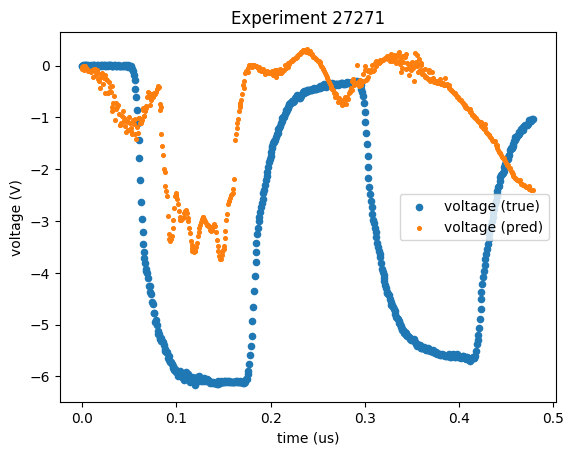

Processing experiment [27271, 27273, 27274, 27275, 27276, 27277, 27278, 27279, 27280, 27281, 27282, 27283, 27284, 27285, 27286, 27287, 27288, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 4.94e-02 | test_loss: 5.16e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:36<00:00,  1.38


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27272...
FLOPs to predict per data point: 50,044.35


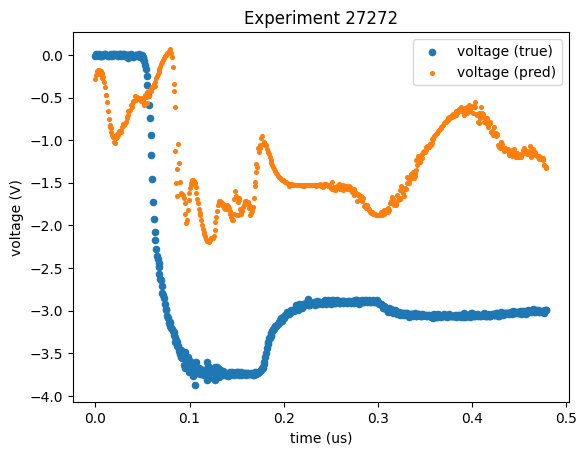

Processing experiment [27271, 27272, 27274, 27275, 27276, 27277, 27278, 27279, 27280, 27281, 27282, 27283, 27284, 27285, 27286, 27287, 27288, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 4.53e-02 | test_loss: 4.40e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:39<00:00,  1.37


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27273...
FLOPs to predict per data point: 50,044.35


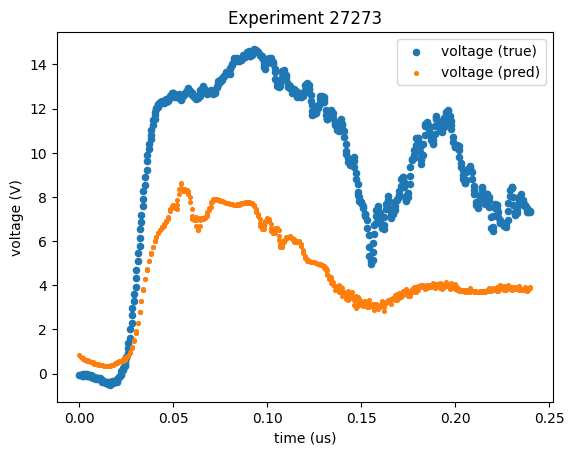

Processing experiment [27271, 27272, 27273, 27275, 27276, 27277, 27278, 27279, 27280, 27281, 27282, 27283, 27284, 27285, 27286, 27287, 27288, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 4.12e-02 | test_loss: 4.36e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:39<00:00,  1.37


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27274...
FLOPs to predict per data point: 50,044.35


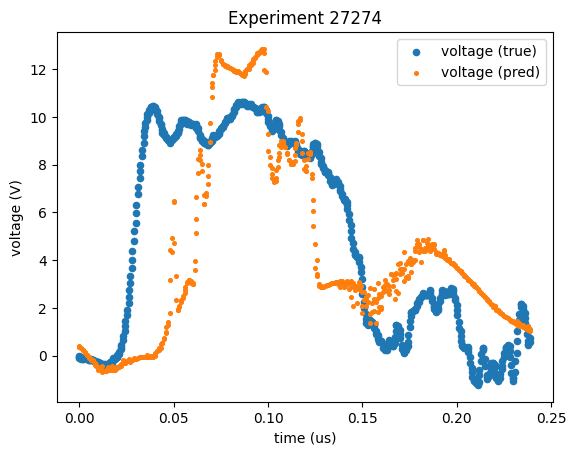

Processing experiment [27271, 27272, 27273, 27274, 27276, 27277, 27278, 27279, 27280, 27281, 27282, 27283, 27284, 27285, 27286, 27287, 27288, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 4.49e-02 | test_loss: 4.54e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:36<00:00,  1.39


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27275...
FLOPs to predict per data point: 50,044.35


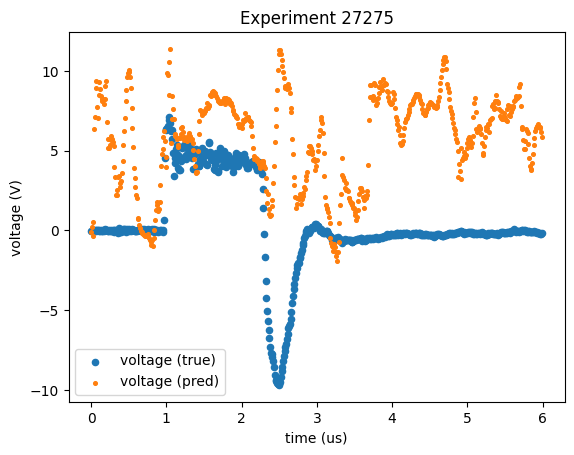

Processing experiment [27271, 27272, 27273, 27274, 27275, 27277, 27278, 27279, 27280, 27281, 27282, 27283, 27284, 27285, 27286, 27287, 27288, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 4.10e-02 | test_loss: 4.75e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:36<00:00,  1.38


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27276...
FLOPs to predict per data point: 50,044.35


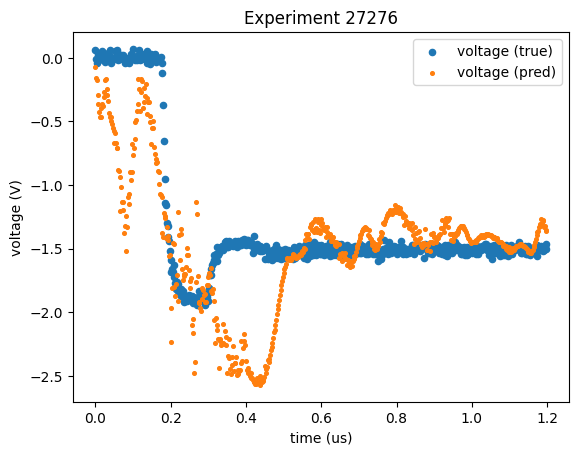

Processing experiment [27271, 27272, 27273, 27274, 27275, 27276, 27278, 27279, 27280, 27281, 27282, 27283, 27284, 27285, 27286, 27287, 27288, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 5.78e-02 | test_loss: 5.38e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:38<00:00,  1.37


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27277...
FLOPs to predict per data point: 50,044.35


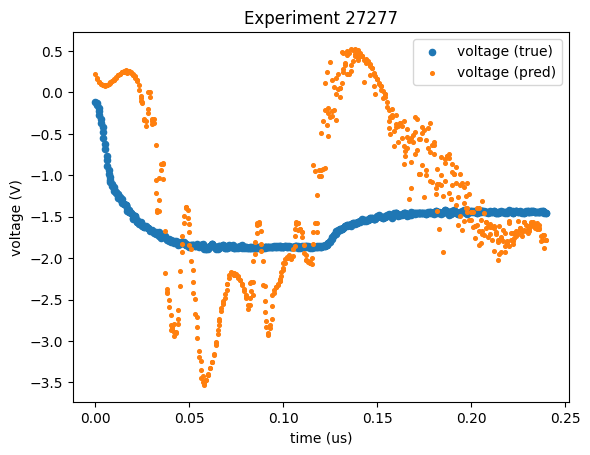

Processing experiment [27271, 27272, 27273, 27274, 27275, 27276, 27277, 27279, 27280, 27281, 27282, 27283, 27284, 27285, 27286, 27287, 27288, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 4.16e-02 | test_loss: 4.54e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:36<00:00,  1.38


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27278...
FLOPs to predict per data point: 50,044.35


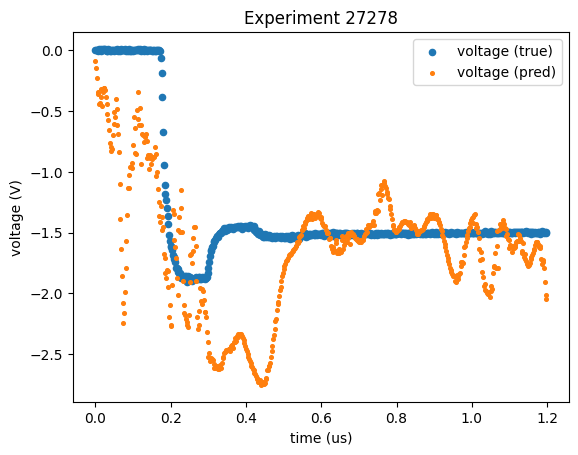

Processing experiment [27271, 27272, 27273, 27274, 27275, 27276, 27277, 27278, 27280, 27281, 27282, 27283, 27284, 27285, 27286, 27287, 27288, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 5.32e-02 | test_loss: 5.32e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:37<00:00,  1.38


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27279...
FLOPs to predict per data point: 50,044.35


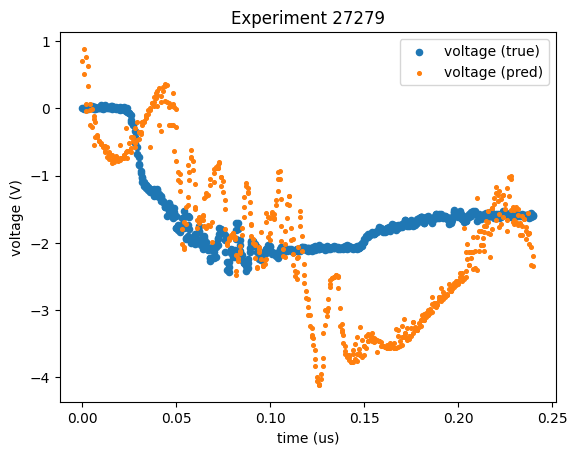

Processing experiment [27271, 27272, 27273, 27274, 27275, 27276, 27277, 27278, 27279, 27281, 27282, 27283, 27284, 27285, 27286, 27287, 27288, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 4.71e-02 | test_loss: 4.94e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:20<00:00,  1.49


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27280...
FLOPs to predict per data point: 50,044.35


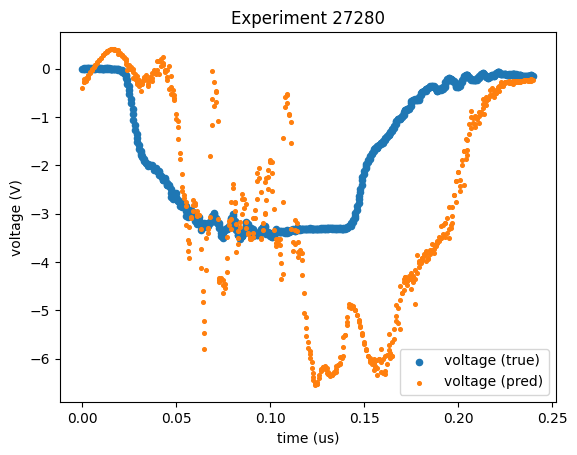

Processing experiment [27271, 27272, 27273, 27274, 27275, 27276, 27277, 27278, 27279, 27280, 27282, 27283, 27284, 27285, 27286, 27287, 27288, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 3.97e-02 | test_loss: 4.98e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:12<00:00,  1.56


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27281...
FLOPs to predict per data point: 50,044.35


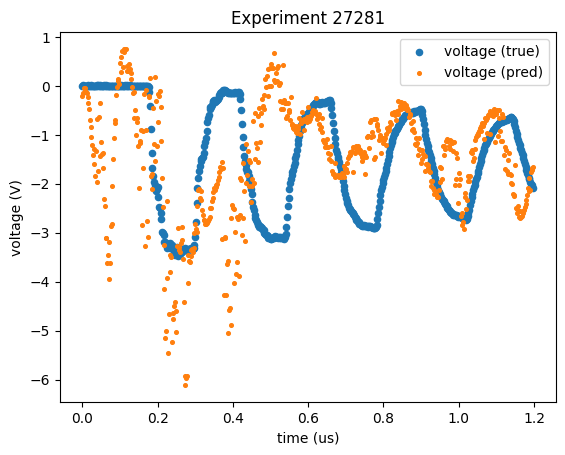

Processing experiment [27271, 27272, 27273, 27274, 27275, 27276, 27277, 27278, 27279, 27280, 27281, 27283, 27284, 27285, 27286, 27287, 27288, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 4.25e-02 | test_loss: 4.51e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:13<00:00,  1.55


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27282...
FLOPs to predict per data point: 50,044.35


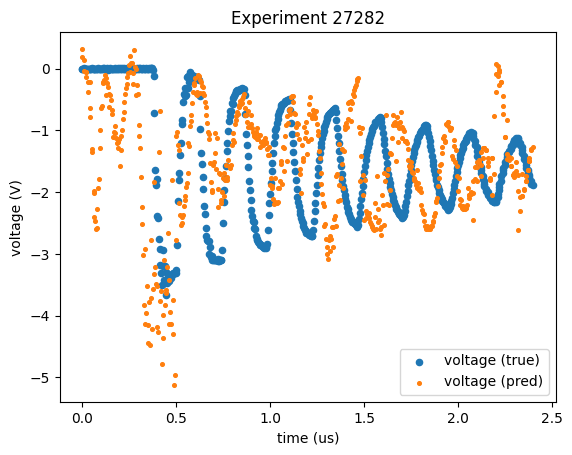

Processing experiment [27271, 27272, 27273, 27274, 27275, 27276, 27277, 27278, 27279, 27280, 27281, 27282, 27284, 27285, 27286, 27287, 27288, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 4.32e-02 | test_loss: 4.40e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:16<00:00,  1.53


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27283...
FLOPs to predict per data point: 50,044.35


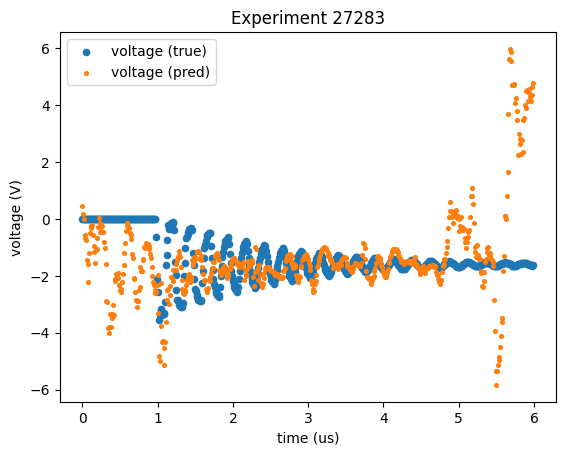

Processing experiment [27271, 27272, 27273, 27274, 27275, 27276, 27277, 27278, 27279, 27280, 27281, 27282, 27283, 27285, 27286, 27287, 27288, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 4.45e-02 | test_loss: 4.47e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:15<00:00,  1.54


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27284...
FLOPs to predict per data point: 50,044.35


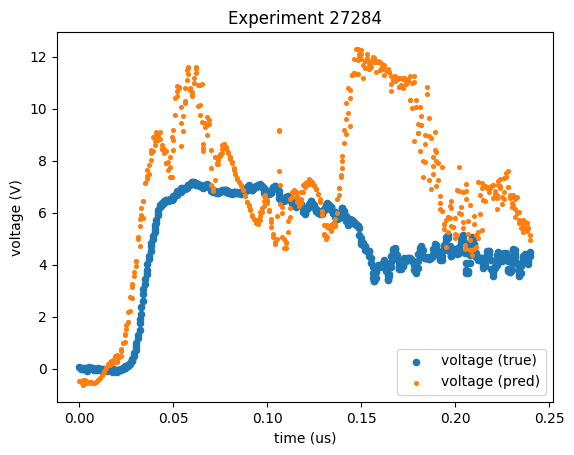

Processing experiment [27271, 27272, 27273, 27274, 27275, 27276, 27277, 27278, 27279, 27280, 27281, 27282, 27283, 27284, 27286, 27287, 27288, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 3.66e-02 | test_loss: 4.22e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [13:07<00:00,  2.63


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27285...
FLOPs to predict per data point: 50,044.35


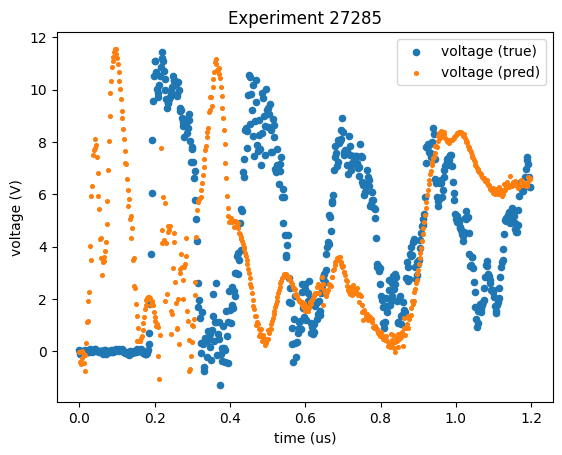

Processing experiment [27271, 27272, 27273, 27274, 27275, 27276, 27277, 27278, 27279, 27280, 27281, 27282, 27283, 27284, 27285, 27287, 27288, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 5.00e-02 | test_loss: 5.09e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:09<00:00,  1.58


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27286...
FLOPs to predict per data point: 50,044.35


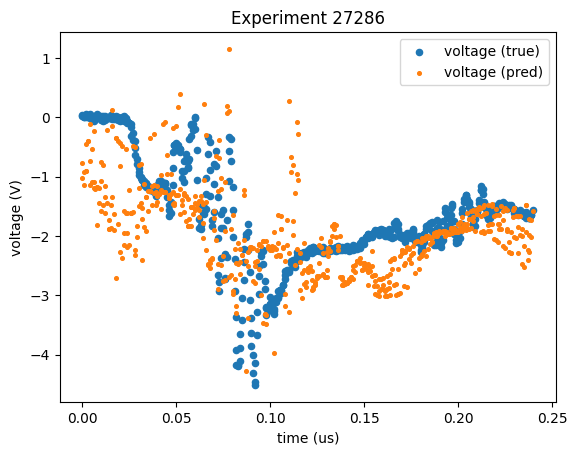

Processing experiment [27271, 27272, 27273, 27274, 27275, 27276, 27277, 27278, 27279, 27280, 27281, 27282, 27283, 27284, 27285, 27286, 27288, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 4.36e-02 | test_loss: 4.40e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:10<00:00,  1.58


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27287...
FLOPs to predict per data point: 50,044.35


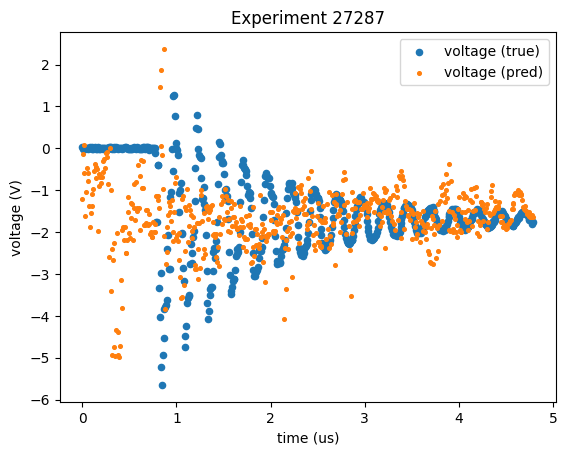

Processing experiment [27271, 27272, 27273, 27274, 27275, 27276, 27277, 27278, 27279, 27280, 27281, 27282, 27283, 27284, 27285, 27286, 27287, 27289, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 3.94e-02 | test_loss: 4.42e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:08<00:00,  1.59


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27288...
FLOPs to predict per data point: 50,044.35


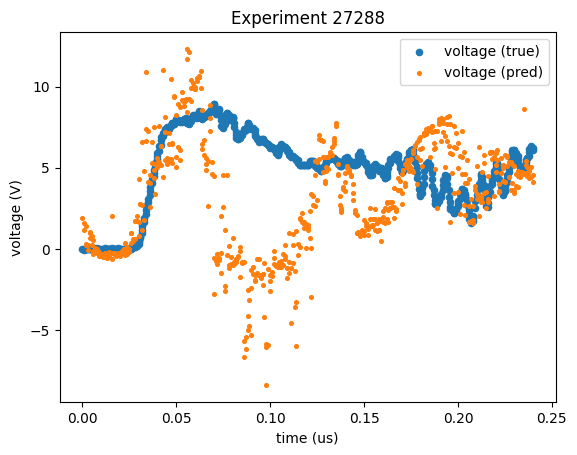

Processing experiment [27271, 27272, 27273, 27274, 27275, 27276, 27277, 27278, 27279, 27280, 27281, 27282, 27283, 27284, 27285, 27286, 27287, 27288, 27306, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 3.62e-02 | test_loss: 3.86e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:08<00:00,  1.59


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27289...
FLOPs to predict per data point: 50,044.35


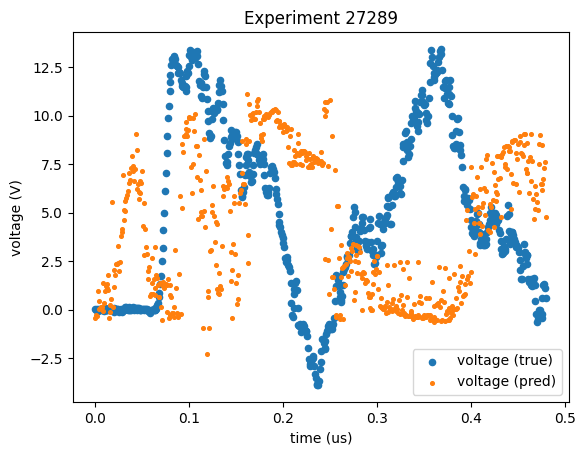

Processing experiment [27271, 27272, 27273, 27274, 27275, 27276, 27277, 27278, 27279, 27280, 27281, 27282, 27283, 27284, 27285, 27286, 27287, 27288, 27289, 27307]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 4.64e-02 | test_loss: 5.08e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:09<00:00,  1.58


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27306...
FLOPs to predict per data point: 50,044.35


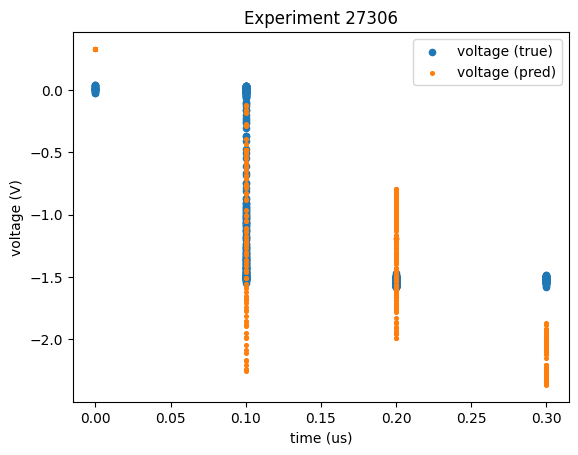

Processing experiment [27271, 27272, 27273, 27274, 27275, 27276, 27277, 27278, 27279, 27280, 27281, 27282, 27283, 27284, 27285, 27286, 27287, 27288, 27289, 27306]...
Training on 90.0% of data
checkpoint directory created: ./model
saving model version 0.0
Points for training: (10800, 4)
Points for testing (1200, 4)


| train_loss: 4.47e-02 | test_loss: 5.08e-02 | reg: 0.00e+00 | : 100%|█| 300/300 [03:08<00:00,  1.59


saving model version 0.1
FLOPs for the training cycle: 0.0
FLOPs for the each point: 0.0
Testing with experiment 27307...
FLOPs to predict per data point: 50,044.35


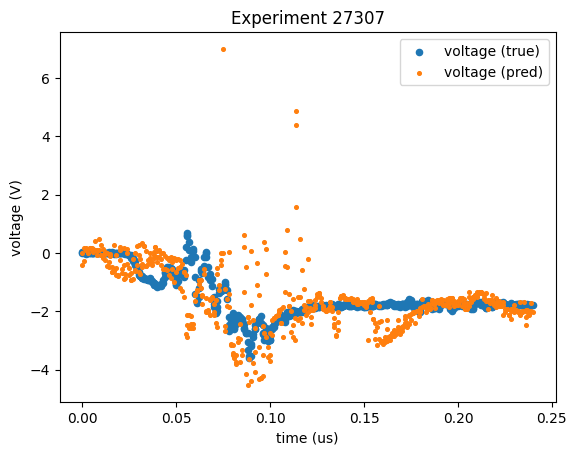

Training Test Error Rates: [4.077, 5.163, 4.405, 4.358, 4.542, 4.748, 5.377, 4.536, 5.322, 4.942, 4.975, 4.511, 4.405, 4.466, 4.217, 5.093, 4.395, 4.417, 3.863, 5.082, 5.079]


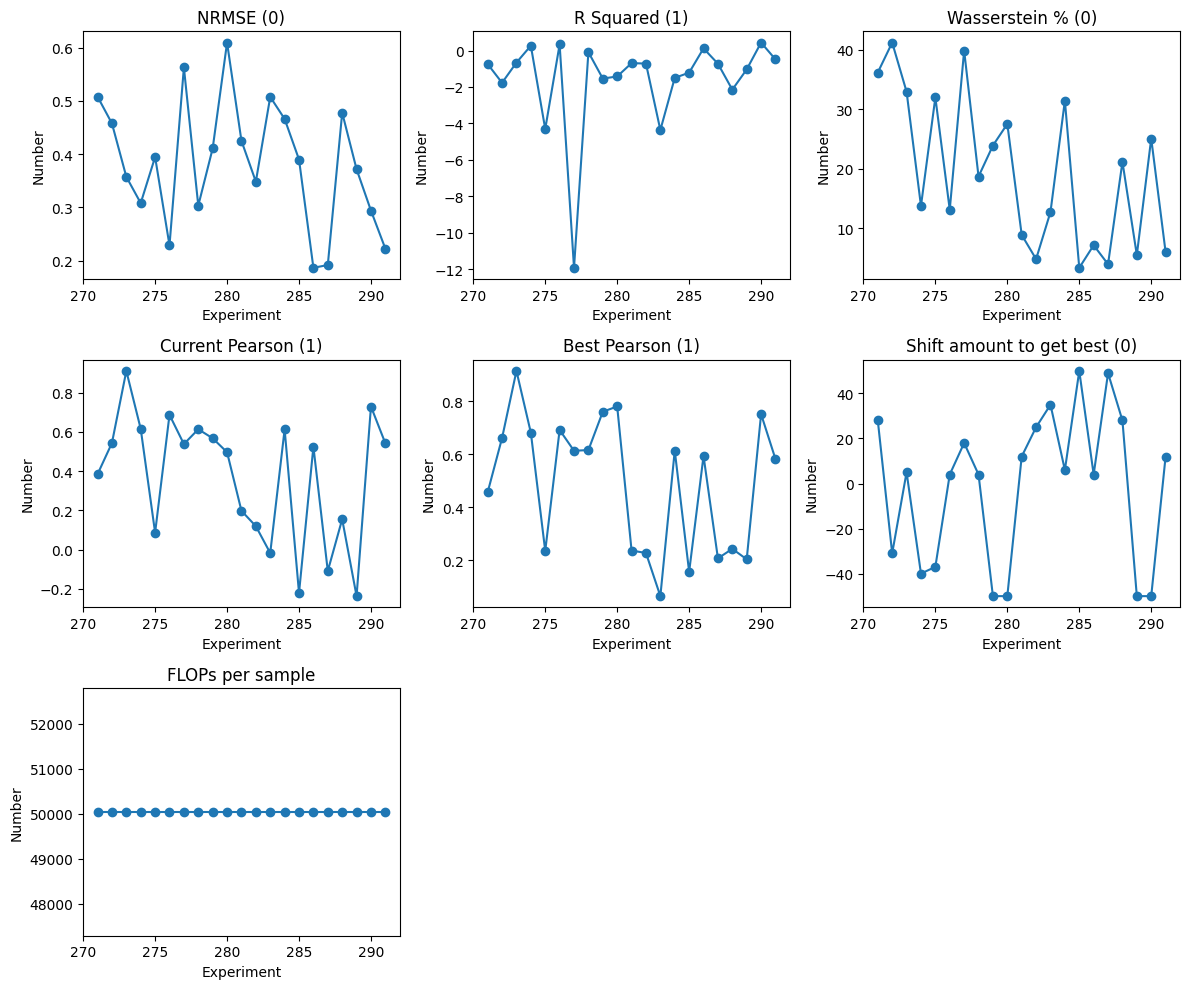

In [38]:

def perform_LOO_training():
    subsets_df = pd.read_csv("training_subsets.csv")
    col_names = ["Name"] + [f"Exp0{i}" for i in range(1, 10)] + [f"Exp{i}" for i in range(10, 21)] + ["Test", "Reasoning"]
    LOO_subsets_df = pd.DataFrame(columns= col_names)

    for i in range(subsets_df.shape[0]):
        row = subsets_df.iloc[i,:].to_list()
        if row[3] == 0: continue # make sure experiment has at least 3 experiments
        for j in row[1:-1]:
            if j == 0: continue
            train = row[1:-1]
            train.remove(j)
            new_row = [row[0]]
            new_row += train
            new_row += [int(j), row[-1]]
            LOO_subsets_df.loc[len(LOO_subsets_df)] = new_row
    
    LOO_subsets_df.to_csv("LOO_training_subsets.csv", index = False)

    perform_training([4,12,14,1], 30, 3, True)


 
perform_LOO_training()

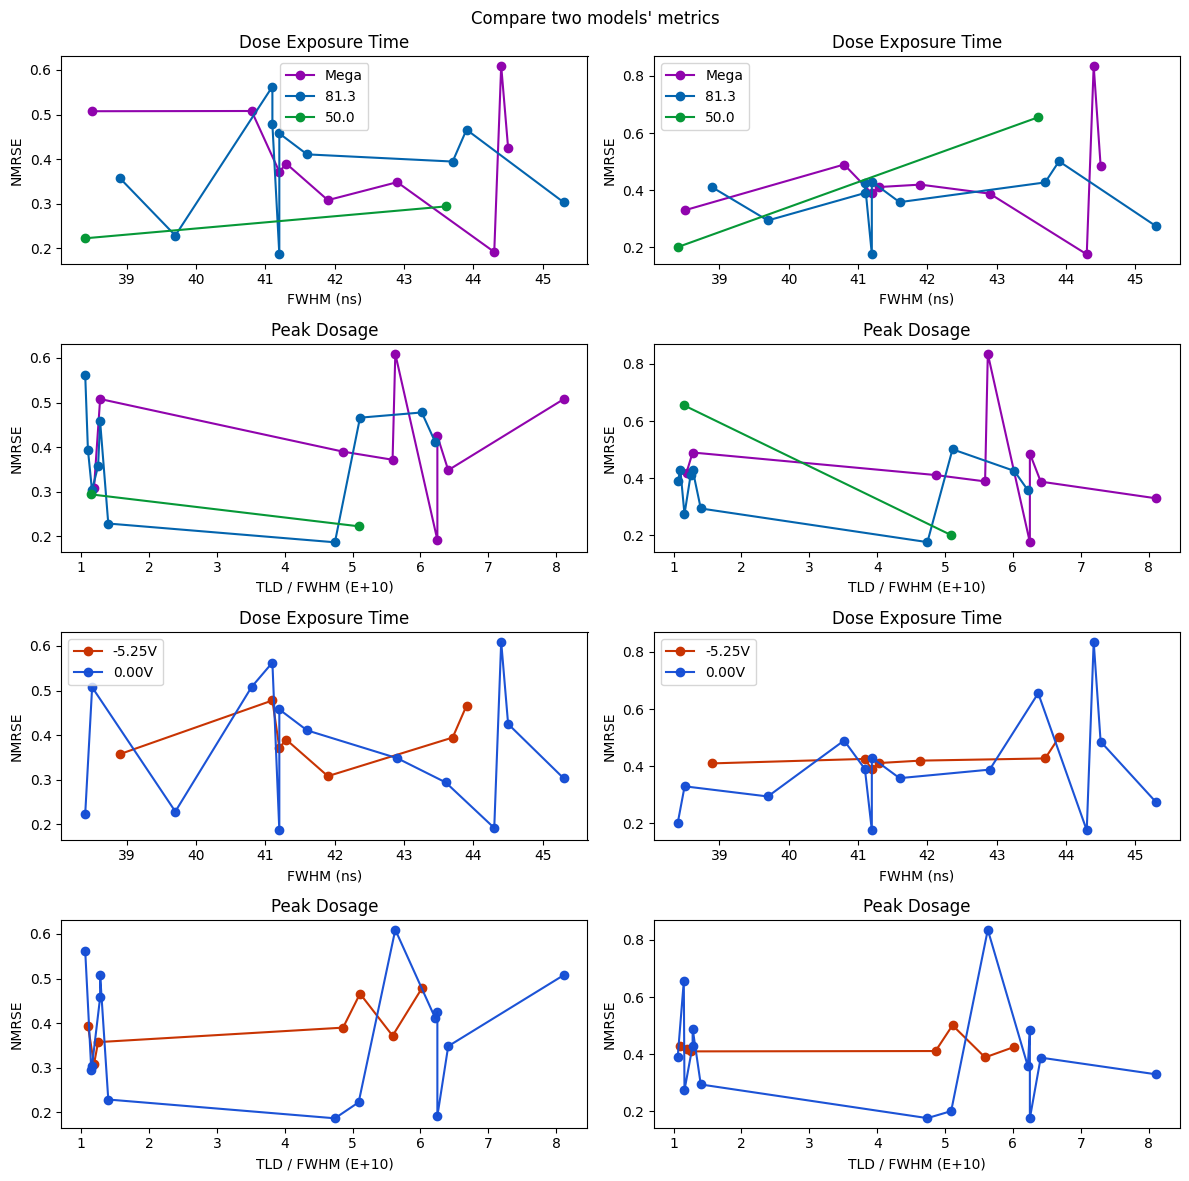

In [42]:
#plot_losses(["final_train_loss_8_new.csv","final_train_loss_8.csv"], [[5,8,1],[4,8,1]])

results_df = pd.read_csv("LOO_metric_results_4-12-14-1.csv")

mega_df = results_df[results_df["Load"] == 1000000].sort_values(by="FWHM (ns)")
eighty_df = results_df[results_df["Load"] == 81.3].sort_values(by="FWHM (ns)")
fifty_df = results_df[results_df["Load"] == 50].sort_values(by="FWHM (ns)")

fig, axes = plt.subplots(4, 2, figsize=(12, 12))
axes = axes.flatten()
fig.suptitle("Compare two models' metrics")

axes[0].plot(mega_df["FWHM (ns)"], mega_df["NRMSE (0)"], marker="o", linestyle="-", c = "#9004AD", label = "Mega")
axes[0].plot(eighty_df["FWHM (ns)"], eighty_df["NRMSE (0)"], marker="o", linestyle="-", c = "#0364AE", label = "81.3")
axes[0].plot(fifty_df["FWHM (ns)"], fifty_df["NRMSE (0)"], marker="o", linestyle="-", c = "#069837", label = "50.0")
axes[0].set_title("Dose Exposure Time")
axes[0].set_xlabel("FWHM (ns)")
axes[0].set_ylabel("NMRSE")
axes[0].legend()

mega_df = mega_df.sort_values(by = "Peak dosage (E+10)")
eighty_df = eighty_df.sort_values(by = "Peak dosage (E+10)")
fifty_df = fifty_df.sort_values(by = "Peak dosage (E+10)")

axes[2].plot(mega_df["Peak dosage (E+10)"], mega_df["NRMSE (0)"], marker="o", linestyle="-", c = "#9004AD")
axes[2].plot(eighty_df["Peak dosage (E+10)"], eighty_df["NRMSE (0)"], marker="o", linestyle="-", c = "#0364AE")
axes[2].plot(fifty_df["Peak dosage (E+10)"], fifty_df["NRMSE (0)"], marker="o", linestyle="-", c = "#069837")
axes[2].set_title("Peak Dosage")
axes[2].set_xlabel("TLD / FWHM (E+10)")
axes[2].set_ylabel("NMRSE")


# Split into two groups by bias   ------------------------------------

yes_bias_df = results_df[results_df["Bias"] == 5.25].sort_values(by="FWHM (ns)")
no_bias_df = results_df[results_df["Bias"] == 0.0].sort_values(by="FWHM (ns)")

axes[4].plot(yes_bias_df["FWHM (ns)"], yes_bias_df["NRMSE (0)"], marker="o", linestyle="-", c = "#C83403", label = "-5.25V")
axes[4].plot(no_bias_df["FWHM (ns)"], no_bias_df["NRMSE (0)"], marker="o", linestyle="-", c = "#154ED5F8", label = "0.00V")
axes[4].set_title("Dose Exposure Time")
axes[4].set_xlabel("FWHM (ns)")
axes[4].set_ylabel("NMRSE")
axes[4].legend()


yes_bias_df = results_df[results_df["Bias"] == 5.25].sort_values(by= "Peak dosage (E+10)")
no_bias_df = results_df[results_df["Bias"] == 0.0].sort_values(by= "Peak dosage (E+10)")

axes[6].plot(yes_bias_df["Peak dosage (E+10)"], yes_bias_df["NRMSE (0)"], marker="o", linestyle="-", c = "#C83403")
axes[6].plot(no_bias_df["Peak dosage (E+10)"], no_bias_df["NRMSE (0)"], marker="o", linestyle="-", c = "#154ED5F8")
axes[6].set_title("Peak Dosage")
axes[6].set_xlabel("TLD / FWHM (E+10)")
axes[6].set_ylabel("NMRSE")


# ===========   Second Model performance =============

results_df = pd.read_csv("LOO_metric_results_4-10-10-1.csv")

mega_df = results_df[results_df["Load"] == 1000000].sort_values(by="FWHM (ns)")
eighty_df = results_df[results_df["Load"] == 81.3].sort_values(by="FWHM (ns)")
fifty_df = results_df[results_df["Load"] == 50].sort_values(by="FWHM (ns)")

axes[1].plot(mega_df["FWHM (ns)"], mega_df["NRMSE (0)"], marker="o", linestyle="-", c = "#9004AD", label = "Mega")
axes[1].plot(eighty_df["FWHM (ns)"], eighty_df["NRMSE (0)"], marker="o", linestyle="-", c = "#0364AE", label = "81.3")
axes[1].plot(fifty_df["FWHM (ns)"], fifty_df["NRMSE (0)"], marker="o", linestyle="-", c = "#069837", label = "50.0")
axes[1].set_title("Dose Exposure Time")
axes[1].set_xlabel("FWHM (ns)")
axes[1].set_ylabel("NMRSE")
axes[1].legend()

mega_df = mega_df.sort_values(by = "Peak dosage (E+10)")
eighty_df = eighty_df.sort_values(by = "Peak dosage (E+10)")
fifty_df = fifty_df.sort_values(by = "Peak dosage (E+10)")

axes[3].plot(mega_df["Peak dosage (E+10)"], mega_df["NRMSE (0)"], marker="o", linestyle="-", c = "#9004AD")
axes[3].plot(eighty_df["Peak dosage (E+10)"], eighty_df["NRMSE (0)"], marker="o", linestyle="-", c = "#0364AE")
axes[3].plot(fifty_df["Peak dosage (E+10)"], fifty_df["NRMSE (0)"], marker="o", linestyle="-", c = "#069837")
axes[3].set_title("Peak Dosage")
axes[3].set_xlabel("TLD / FWHM (E+10)")
axes[3].set_ylabel("NMRSE")


# Split into two groups by bias   ------------------------------------

yes_bias_df = results_df[results_df["Bias"] == 5.25].sort_values(by="FWHM (ns)")
no_bias_df = results_df[results_df["Bias"] == 0.0].sort_values(by="FWHM (ns)")

axes[5].plot(yes_bias_df["FWHM (ns)"], yes_bias_df["NRMSE (0)"], marker="o", linestyle="-", c = "#C83403", label = "-5.25V")
axes[5].plot(no_bias_df["FWHM (ns)"], no_bias_df["NRMSE (0)"], marker="o", linestyle="-", c = "#154ED5F8", label = "0.00V")
axes[5].set_title("Dose Exposure Time")
axes[5].set_xlabel("FWHM (ns)")
axes[5].set_ylabel("NMRSE")
axes[5].legend()


yes_bias_df = results_df[results_df["Bias"] == 5.25].sort_values(by= "Peak dosage (E+10)")
no_bias_df = results_df[results_df["Bias"] == 0.0].sort_values(by= "Peak dosage (E+10)")

axes[7].plot(yes_bias_df["Peak dosage (E+10)"], yes_bias_df["NRMSE (0)"], marker="o", linestyle="-", c = "#C83403")
axes[7].plot(no_bias_df["Peak dosage (E+10)"], no_bias_df["NRMSE (0)"], marker="o", linestyle="-", c = "#154ED5F8")
axes[7].set_title("Peak Dosage")
axes[7].set_xlabel("TLD / FWHM (E+10)")
axes[7].set_ylabel("NMRSE")


plt.tight_layout()
plt.show()


